In [20]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'cartpole.py').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import control
import cartpole as cp
import importlib, controllers; importlib.reload(controllers)
from controllers import lqr_continuous, LQRController, CascadePID, run_closed_loop
from controllers import MPCController

P = cp.CartPoleParams()
A, B = cp.analytic_AB(P)          # Aşama 2'deki doğrusal model, dik konum

## Q ve R (Bryson kuralı) ve K:

In [2]:
# Bryson: Q_ii = 1 / (izin verdiğim en büyük değer)²,  R = 1 / F_max²
x_max, xd_max, th_max, thd_max, F_max = 0.5, 1.0, 0.2, 1.0, 10.0
Q = np.diag([1/x_max**2, 1/xd_max**2, 1/th_max**2, 1/thd_max**2])    # köşegen 4×4 → [4, 1, 25, 1]
R = np.array([[1/F_max**2]])                                          # 1×1 → 0.01

K, Pmat = lqr_continuous(A, B, Q, R)        
K_ref, _, _ = control.lqr(A, B, Q, R)         # hazır kütüphane

print("K (benim)     :", np.round(K, 2))
print("K (control)   :", np.round(K_ref, 2))
print("en büyük fark :", np.abs(K - K_ref).max())

K (benim)     : [[ -20.    -23.72 -124.23  -27.33]]
K (control)   : [[ -20.    -23.72 -124.23  -27.33]]
en büyük fark : 0.0


Kutup yerleştirmede kutupları biz seçiyorduk. Burada LQR seçti. Hepsinin gerçel kısmı negatif mi? Garanti: (A, B) kontrol edilebilir olduğu için LQR her zaman kararlı bir kapalı döngü verir.

In [3]:
lam = np.linalg.eigvals(A - B @ K)
print("kapalı döngü özdeğerleri:", np.round(np.sort_complex(lam), 2))

kapalı döngü özdeğerleri: [-22.69+0.j   -4.98+0.j   -1.63-0.9j  -1.63+0.9j]


Karşılaştırma:

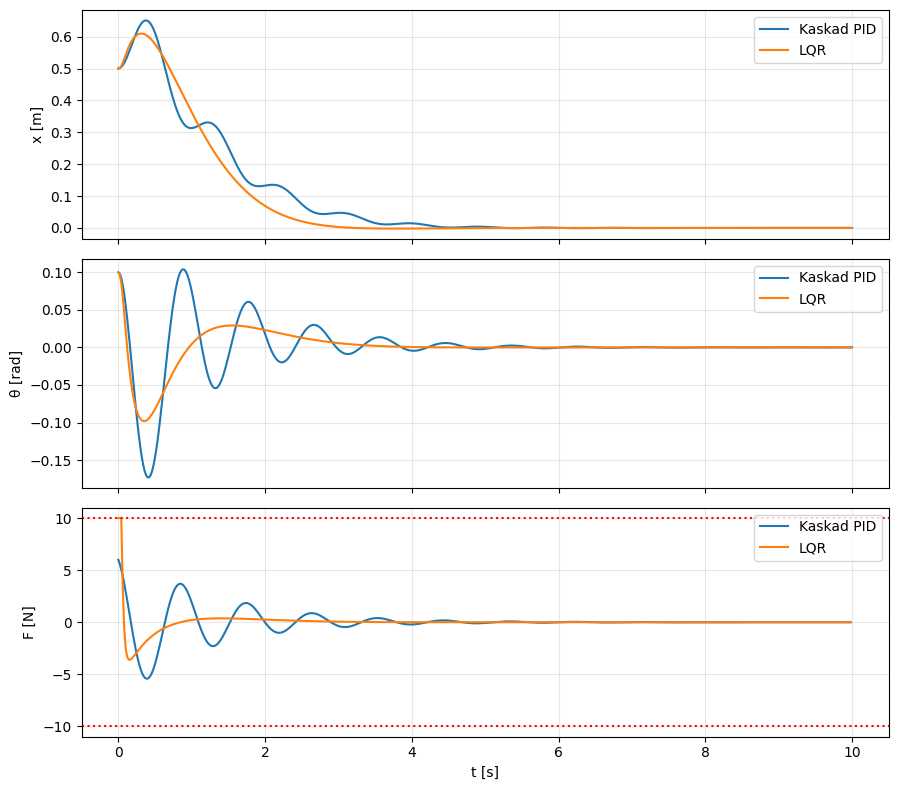

In [4]:
s0 = [0.5, 0, 0.1, 0]                      # Aşama 3'teki senaryonun aynısı
kontrolculer = {
    "Kaskad PID": CascadePID(),
    "LQR":        LQRController(K),
}

sonuclar = {}
for ad, ctrl in kontrolculer.items():
    t, S, U = run_closed_loop(ctrl, s0, T=10.0, F_max=10.0)
    sonuclar[ad] = (t, S, U)

fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ad, (t, S, U) in sonuclar.items():
    ax[0].plot(t, S[:, 0], label=ad)
    ax[1].plot(t, S[:, 2], label=ad)
    ax[2].plot(t[:-1], U, label=ad)
ax[0].set_ylabel("x [m]"); ax[1].set_ylabel("θ [rad]"); ax[2].set_ylabel("F [N]"); ax[2].set_xlabel("t [s]")
ax[2].axhline(10, color="r", ls=":"); ax[2].axhline(-10, color="r", ls=":")
for a in ax: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

In [5]:
def oturma_suresi(t, x, tol=0.02):
    """x'in en son ne zaman ±tol dışında olduğu (ondan sonra hep içeride)."""
    disarida = np.where(np.abs(x) > tol)[0]
    return t[disarida[-1]] if len(disarida) else 0.0

print(f"{'kontrolcü':12s} | {'oturma (±2 cm)':>14s} | {'max |F|':>8s} | {'∫F² dt':>8s}")
for ad, (t, S, U) in sonuclar.items():
    print(f"{ad:12s} | {oturma_suresi(t, S[:, 0]):12.2f} s | {np.abs(U).max():6.1f} N | {np.sum(U**2) * 0.02:8.2f}")

kontrolcü    | oturma (±2 cm) |  max |F| |   ∫F² dt
Kaskad PID   |         3.42 s |    6.0 N |    15.18
LQR          |         2.50 s |   10.0 N |     9.17


In [7]:
dt = 0.02
A_d, B_d = cp.discretize(A, B, dt)        # ZOH ayrıklaştırma ( e^{At})
Q_d, R_d = Q * dt, R * dt                  # sürekli ∫(...)dt'nin ayrık toplamı: her adımda × dt

P_it = Q_d.copy()                          # başlangıç: "hiç adım kalmadıysa ceza sadece sᵀQs"
for k in range(20000):
    K_d = np.linalg.solve(R_d + B_d.T @ P_it @ B_d, B_d.T @ P_it @ A_d)        # (R_d + B_dᵀ P B_d)⁻¹ B_dᵀ P A_d
    P_yeni = Q_d + A_d.T @ P_it @ A_d - A_d.T @ P_it @ B_d @ K_d      # Q_d + A_dᵀ P A_d − A_dᵀ P B_d K_d
    fark = np.abs(P_yeni - P_it).max()
    P_it = P_yeni
    if k % 10 == 0:
        print(f"{k} iterasyon, K_d= {K_d}")
    if fark < 1e-10:                       # P artık değişmiyor → yakınsadı
        break
print("yakınsama:", k + 1, "iterasyon")
print("K_d (elle)  :", np.round(K_d, 2))

0 iterasyon, K_d= [[ 0.06662173  1.66698462 -2.31153417 -3.36708889]]
10 iterasyon, K_d= [[  1.76218589   2.01752441 -36.86314541  -9.39992072]]
20 iterasyon, K_d= [[  1.06558812  -1.44786964 -54.81802239 -11.86049698]]
30 iterasyon, K_d= [[ -1.79507334  -5.2914067  -66.02951176 -14.15080749]]
40 iterasyon, K_d= [[ -5.54673611  -9.11749697 -75.61068686 -16.33977021]]
50 iterasyon, K_d= [[ -8.9967171  -12.36224975 -83.49711692 -18.17952354]]
60 iterasyon, K_d= [[-11.48101351 -14.64849309 -89.01859824 -19.47305511]]
70 iterasyon, K_d= [[-12.99136563 -16.0354414  -92.3627743  -20.25745956]]
80 iterasyon, K_d= [[-13.81923441 -16.79795793 -94.20048066 -20.68872499]]
90 iterasyon, K_d= [[-14.24924085 -17.19451961 -95.15608335 -20.91301884]]
100 iterasyon, K_d= [[-14.46825887 -17.39559069 -95.64058629 -21.02672144]]
110 iterasyon, K_d= [[-14.58013573 -17.49704514 -95.88504507 -21.08406239]]
120 iterasyon, K_d= [[-14.63822533 -17.54869866 -96.00950205 -21.11323167]]
130 iterasyon, K_d= [[-14.6

Hazır çözümle karşılaştırma

In [10]:
from scipy.linalg import solve_discrete_are

P_hazir = solve_discrete_are(A_d, B_d, Q_d, R_d)           # scipy: discrete Riccati'yi doğrudan çözer
K_hazir, _, _ = control.dlqr(A_d, B_d, Q_d, R_d)           # python-control: discrete LQR

print("P farkı (elle − scipy)   :", np.abs(P_it - P_hazir).max())
print("K_d farkı (elle − dlqr)  :", np.abs(K_d - K_hazir).max())
print()
print("K continuous    :", np.round(K, 2))
print("K_d discrete (elle)         :", np.round(K_d, 2))
print("oran K_d / K             :", np.round(K_d / K, 2))

P farkı (elle − scipy)   : 1.4027818906470202e-09
K_d farkı (elle − dlqr)  : 5.315015982887417e-09

K continuous    : [[ -20.    -23.72 -124.23  -27.33]]
K_d discrete (elle)         : [[-14.71 -17.61 -96.15 -21.15]]
oran K_d / K             : [[0.74 0.74 0.77 0.77]]


P sağlıklı mı?

In [11]:
ozd_P = np.linalg.eigvalsh(P_it)          # eigvalsh: SİMETRİK matrisler için (P simetrik olmalı)
print("P simetrik mi?        :", np.allclose(P_it, P_it.T))
print("P'nin özdeğerleri     :", np.round(ozd_P, 4))
print("hepsi pozitif mi?     :", np.all(ozd_P > 0))

P simetrik mi?        : True
P'nin özdeğerleri     : [ 0.0556  0.6028  3.0898 23.5324]
hepsi pozitif mi?     : True


Değer fonksiyonunu doğrula, V(s₀) = s₀ᵀ P s₀

In [12]:
s0 = np.array([0.3, 0.0, 0.05, 0.0])
s = s0.copy()
toplam_ceza = 0.0
for _ in range(5000):                                  # 5000 × 0.02 s = 100 s → ceza artık birikmiyor
    u = -K_d @ s                                       # LQR'nin kararı
    toplam_ceza += s @ Q_d @ s + u @ R_d @ u           # bu adımın cezası: sᵀQs + uᵀRu
    s = A_d @ s + B_d @ u                              # ayrık doğrusal model: bir adım ilerle

V_formul = s0 @ P_it @ s0                              # değer fonksiyonu formülü
print(f"simülasyonla ödenen toplam ceza : {toplam_ceza:.10f}")
print(f"formül  s0ᵀ·P·s0               : {V_formul:.10f}")
print(f"fark                           : {abs(toplam_ceza - V_formul):.2e}")

simülasyonla ödenen toplam ceza : 0.6446394191
formül  s0ᵀ·P·s0               : 0.6446394190
fark                           : 5.96e-11


In [13]:
P_b = Q_d.copy()
for k in range(1, 401):
    K_b = np.linalg.solve(R_d + B_d.T @ P_b @ B_d, B_d.T @ P_b @ A_d)
    P_b = Q_d + A_d.T @ P_b @ A_d - A_d.T @ P_b @ B_d @ K_b
    if k in (1, 10, 50, 100, 200, 400):
        print(f"k = {k:3d} adım ileriye bakıyor:  K = {np.round(K_b, 1)}   ({k * dt:.2f} s)")

k =   1 adım ileriye bakıyor:  K = [[ 0.1  1.7 -2.3 -3.4]]   (0.02 s)
k =  10 adım ileriye bakıyor:  K = [[  1.7   2.3 -34.3  -9.1]]   (0.20 s)
k =  50 adım ileriye bakıyor:  K = [[ -8.7 -12.1 -82.8 -18. ]]   (1.00 s)
k = 100 adım ileriye bakıyor:  K = [[-14.5 -17.4 -95.6 -21. ]]   (2.00 s)
k = 200 adım ileriye bakıyor:  K = [[-14.7 -17.6 -96.1 -21.1]]   (4.00 s)
k = 400 adım ileriye bakıyor:  K = [[-14.7 -17.6 -96.1 -21.1]]   (8.00 s)


ayar     |                                  K |  oturma | max|θ| | max|F| |  ∫F²dt | yavaş kutup
Bryson   |        [[-14.7 -17.6 -96.1 -21.1]] |  2.50 s |  0.100 |   10.0 |   8.00 |    -1.63
qθ ×10   |    [[ -14.   -21.4 -154.   -24.9]] |  3.30 s |  0.100 |   10.0 |   8.87 |    -0.86
qx ×10   |    [[ -45.5  -35.1 -138.2  -30.8]] |  1.40 s |  0.213 |   10.0 |  25.78 |    -2.84
R ×10    |        [[ -5.4  -7.  -49.4 -10.8]] |  2.66 s |  0.100 |    7.6 |   3.96 |    -1.49
R ÷10    |    [[ -30.1  -35.1 -174.7  -38.4]] |  2.48 s |  0.100 |   10.0 |  10.38 |    -1.65


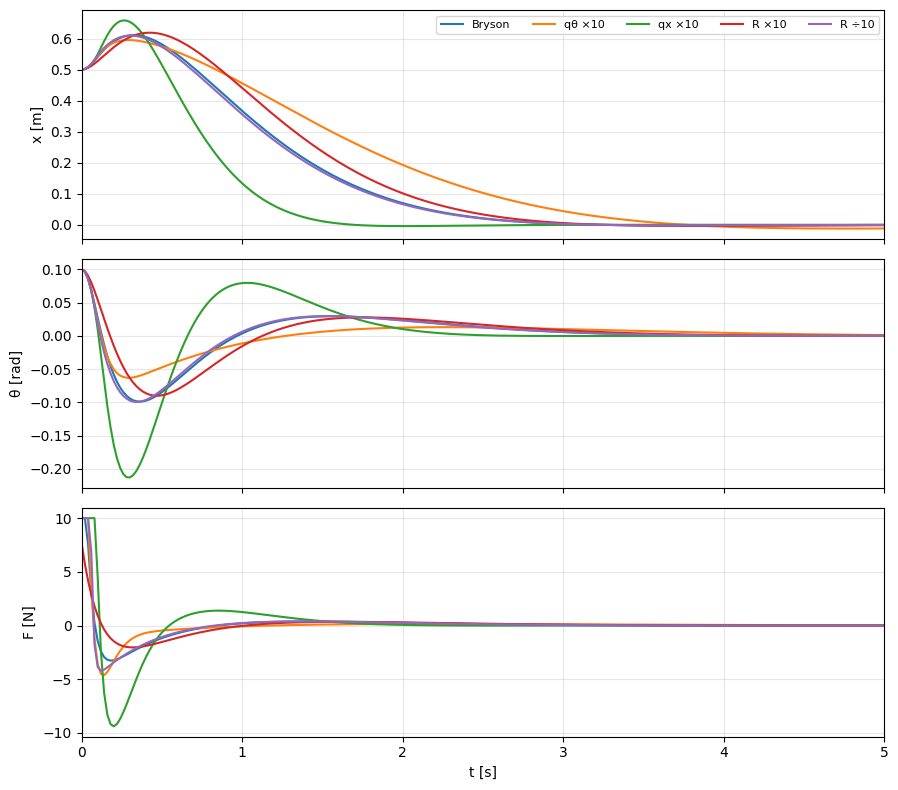

In [14]:
import importlib, controllers; importlib.reload(controllers)
from controllers import lqr_discrete, LQRController, run_closed_loop

dt = 0.02
A_d, B_d = cp.discretize(A, B, dt)
q_bryson = np.array([4.0, 1.0, 25.0, 1.0])            # [x, ẋ, θ, θ̇]

ayarlar = {                                           # ad: (Q köşegeni, R)
    "Bryson":  (q_bryson,                 0.01),
    "qθ ×10":  (q_bryson * [1, 1, 10, 1], 0.01),
    "qx ×10":  (q_bryson * [10, 1, 1, 1], 0.01),
    "R ×10":   (q_bryson,                 0.1),
    "R ÷10":   (q_bryson,                 0.001),
}

def oturma_suresi(t, x, tol=0.02):
    disarida = np.where(np.abs(x) > tol)[0]
    return t[disarida[-1]] if len(disarida) else 0.0

s0 = [0.5, 0, 0.1, 0]
sonuclar = {}
print(f"{'ayar':8s} | {'K':>34s} | {'oturma':>7s} | {'max|θ|':>6s} | {'max|F|':>6s} | {'∫F²dt':>6s} | {'yavaş kutup':>11s}")
for ad, (q, r) in ayarlar.items():
    K_i, _ = lqr_discrete(A_d, B_d, np.diag(q), np.array([[r]]), dt)
    z = np.linalg.eigvals(A_d - B_d @ K_i)
    yavas = np.log(np.abs(z)).max() / dt              # ayrık z → sürekli eşdeğer σ = ln|z| / dt
    t, S, U = run_closed_loop(LQRController(K_i), s0, T=10.0, F_max=10.0)
    sonuclar[ad] = (t, S, U)
    print(f"{ad:8s} | {str(np.round(K_i, 1)):>34s} | {oturma_suresi(t, S[:, 0]):5.2f} s | "
          f"{np.abs(S[:, 2]).max():6.3f} | {np.abs(U).max():6.1f} | {np.sum(U**2) * dt:6.2f} | {yavas:8.2f}")

fig, ax = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for ad, (t, S, U) in sonuclar.items():
    ax[0].plot(t, S[:, 0], label=ad); ax[1].plot(t, S[:, 2], label=ad); ax[2].plot(t[:-1], U, label=ad)
ax[0].set_ylabel("x [m]"); ax[1].set_ylabel("θ [rad]"); ax[2].set_ylabel("F [N]"); ax[2].set_xlabel("t [s]")
ax[0].legend(ncol=5, fontsize=8)
for a in ax: a.grid(alpha=0.3)
ax[0].set_xlim(0, 5)
plt.tight_layout(); plt.show()

In [15]:
import importlib, controllers; importlib.reload(controllers)
from controllers import AnglePD, CascadePID, LQRController, lqr_discrete, run_closed_loop

dt = 0.02
A_d, B_d = cp.discretize(A, B, dt)
q = np.diag([4.0, 1.0, 25.0, 1.0])
K_bry, _ = lqr_discrete(A_d, B_d, q, np.array([[0.01]]), dt)
K_r10, _ = lqr_discrete(A_d, B_d, q, np.array([[0.1]]),  dt)

def basarili(S, x_sinir=2.4):
    """Kurtarma tanımı (KARARLAR.md): sonlu, ray içinde, sonunda dik ve sakin."""
    if not np.all(np.isfinite(S)):            # simülasyon patladı mı?
        return False
    return (np.abs(S[:, 0]).max() <= x_sinir  # hiçbir an raydan çıkmadı
            and abs(S[-1, 2]) < 0.05          # sonunda dik
            and abs(S[-1, 3]) < 0.1)          # ve sakin

kontrolculer = {                              # her biri YENİ bir nesne üretir (lambda) → hafıza paylaşılmaz
    "AnglePD":    lambda: AnglePD(Kp=20, Kd=3),
    "Kaskad":     lambda: CascadePID(),
    "LQR Bryson": lambda: LQRController(K_bry),
    "LQR R×10":   lambda: LQRController(K_r10),
}
acilar = np.arange(0, 91)                     # derece

sonuc = {}                                    # (ad, F_max) → her açı için True/False
with np.errstate(all="ignore"):               # patlayan simülasyonların uyarılarını sustur (zaten başarısız sayıyoruz)
    for ad, yap in kontrolculer.items():
        for F_max in (10.0, None):
            sonuc[(ad, F_max)] = [basarili(run_closed_loop(yap(), [0, 0, np.radians(d), 0],
                                                           T=10.0, F_max=F_max, substeps=5)[1])
                                  for d in acilar]
            ilk_hata = next((d for d, b in zip(acilar, sonuc[(ad, F_max)]) if not b), None)
            print(f"{ad:11s} | F_max={str(F_max):5s} | ilk başarısız açı: {ilk_hata}°")

AnglePD     | F_max=10.0  | ilk başarısız açı: 5°
AnglePD     | F_max=None  | ilk başarısız açı: 5°
Kaskad      | F_max=10.0  | ilk başarısız açı: 36°
Kaskad      | F_max=None  | ilk başarısız açı: 50°
LQR Bryson  | F_max=10.0  | ilk başarısız açı: 32°
LQR Bryson  | F_max=None  | ilk başarısız açı: 61°
LQR R×10    | F_max=10.0  | ilk başarısız açı: 36°
LQR R×10    | F_max=None  | ilk başarısız açı: 57°


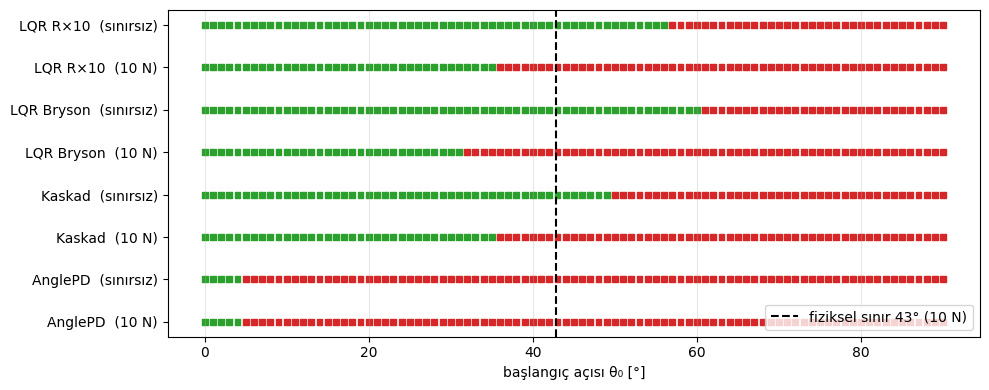

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
satirlar = list(sonuc.keys())
for i, (ad, F_max) in enumerate(satirlar):
    renk = ["tab:green" if b else "tab:red" for b in sonuc[(ad, F_max)]]
    ax.scatter(acilar, [i] * len(acilar), c=renk, marker="s", s=18)
ax.set_yticks(range(len(satirlar)))
ax.set_yticklabels([f"{ad}  ({'10 N' if F else 'sınırsız'})" for ad, F in satirlar])
ax.axvline(np.degrees(np.arctan(10 / ((P.M + P.m) * P.g))), color="k", ls="--", label="fiziksel sınır 43° (10 N)")
ax.set_xlabel("başlangıç açısı θ₀ [°]"); ax.legend(loc="lower right"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

Kaskad     : ızgaranın %53.9'i kurtarıldı
LQR Bryson : ızgaranın %48.4'i kurtarıldı
LQR R×10   : ızgaranın %53.0'i kurtarıldı


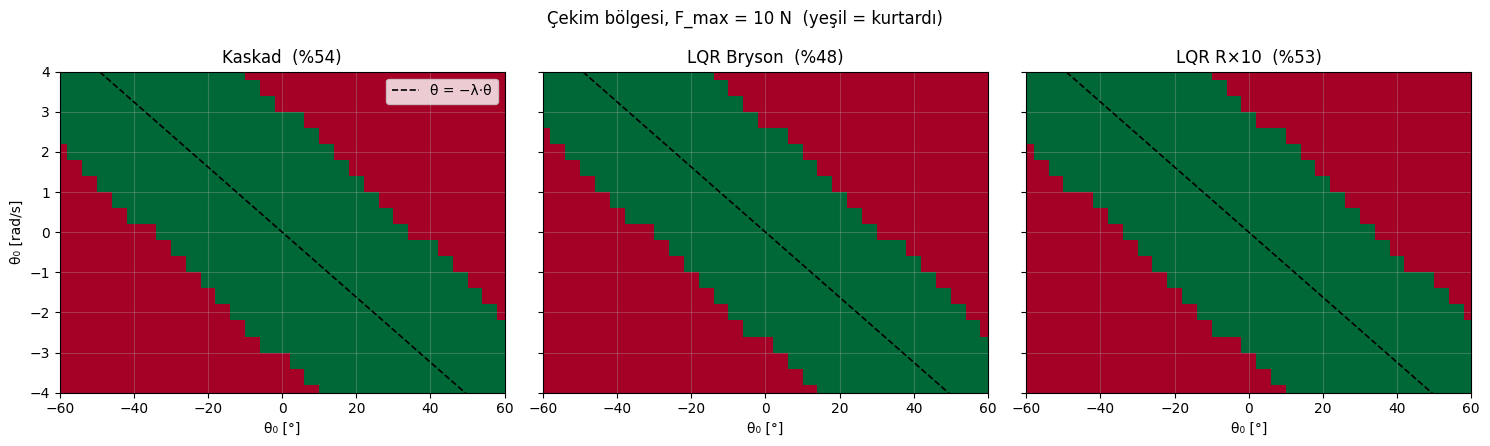

In [17]:
# --- Izgara: θ₀ ∈ [−60°, 60°], θ̇₀ ∈ [−4, 4] rad/s ---
th_deg = np.arange(-60, 61, 4)                 # 31 açı
thd    = np.arange(-4.0, 4.01, 0.4)            # 21 açısal hız
secilen = {"Kaskad": kontrolculer["Kaskad"],
           "LQR Bryson": kontrolculer["LQR Bryson"],
           "LQR R×10": kontrolculer["LQR R×10"]}

haritalar = {}
with np.errstate(all="ignore"):
    for ad, yap in secilen.items():
        G = np.zeros((len(thd), len(th_deg)), dtype=bool)        # satır: θ̇₀, sütun: θ₀
        for i, w in enumerate(thd):
            for j, a in enumerate(th_deg):
                _, S, _ = run_closed_loop(yap(), [0, 0, np.radians(a), w], T=10.0, F_max=10.0, substeps=5)
                G[i, j] = basarili(S)
        haritalar[ad] = G
        print(f"{ad:11s}: ızgaranın %{100 * G.mean():.1f}'i kurtarıldı")

# --- Çizim ---
lam = np.sqrt((P.M + P.m) * P.g / (P.M * P.l))                  # Aşama 2'deki kararsız özdeğer ≈ 4.65
fig, axs = plt.subplots(1, len(haritalar), figsize=(15, 4.5), sharey=True)
for ax, (ad, G) in zip(axs, haritalar.items()):
    ax.pcolormesh(th_deg, thd, G, cmap="RdYlGn", vmin=0, vmax=1, shading="nearest")
    ax.plot(th_deg, -lam * np.radians(th_deg), "k--", lw=1.2, label="θ̇ = −λ·θ")
    ax.set_xlim(-60, 60); ax.set_ylim(-4, 4)
    ax.set_title(f"{ad}  (%{100 * G.mean():.0f})"); ax.set_xlabel("θ₀ [°]"); ax.grid(alpha=0.3)
axs[0].set_ylabel("θ̇₀ [rad/s]"); axs[0].legend(loc="upper right")
plt.suptitle("Çekim bölgesi, F_max = 10 N  (yeşil = kurtardı)"); plt.tight_layout(); plt.show()

# MPC

In [21]:

dt = 0.02
A_d, B_d = cp.discretize(A, B, dt)
Q = np.diag([4.0, 1.0, 25.0, 1.0]); R = np.array([[0.01]])
K_d, P_d = lqr_discrete(A_d, B_d, Q, R, dt)

mpc = MPCController(A_d, B_d, Q, R, P_d, N=10, dt=dt, F_max=10.0, x_max=2.4, K_yedek=K_d)

# MPC = LQR testi: küçük sapmalar (kısıtlar aktif değil)
rng = np.random.default_rng(0)
for _ in range(5):
    s = rng.uniform([-0.1, -0.1, -0.03, -0.1], [0.1, 0.1, 0.03, 0.1])
    print(f"MPC: {mpc.act(s):+.6f}   LQR: {float(-(K_d @ s)[0]):+.6f}")

MPC: -5.100571   LQR: -5.100567
MPC: +3.960565   LQR: +3.960568
MPC: +1.379465   LQR: +1.379458
MPC: -0.637570   LQR: -0.638009
MPC: -0.268240   LQR: -0.268226


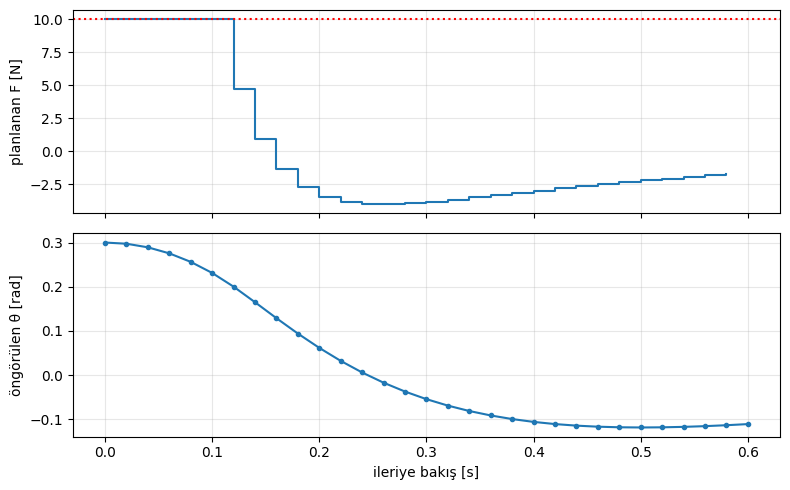

uygulanacak tek kuvvet: 10.000000024857886    LQR olsaydı (kırpılmadan): 28.844537654294925


In [22]:
mpc30 = MPCController(A_d, B_d, Q, R, P_d, N=30, dt=dt, F_max=10.0, x_max=2.4, K_yedek=K_d)
s0 = np.array([0.0, 0.0, 0.3, 0.0])                # 17° yatık: kısıtın AKTİF olacağı bir durum
F0 = mpc30.act(s0)

u_plan  = mpc30.U.value[0]                         # planlanan 30 kuvvet
th_plan = mpc30.S.value[2]                         # öngörülen 31 açı (s_0 … s_30)
t_plan  = np.arange(31) * dt

fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax[0].step(t_plan[:-1], u_plan, where="post"); ax[0].axhline(10, color="r", ls=":")
ax[0].set_ylabel("planlanan F [N]")
ax[1].plot(t_plan, th_plan, "o-", ms=3); ax[1].set_ylabel("öngörülen θ [rad]"); ax[1].set_xlabel("ileriye bakış [s]")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("uygulanacak tek kuvvet:", F0, "   LQR olsaydı (kırpılmadan):", float(-(K_d @ s0)[0]))

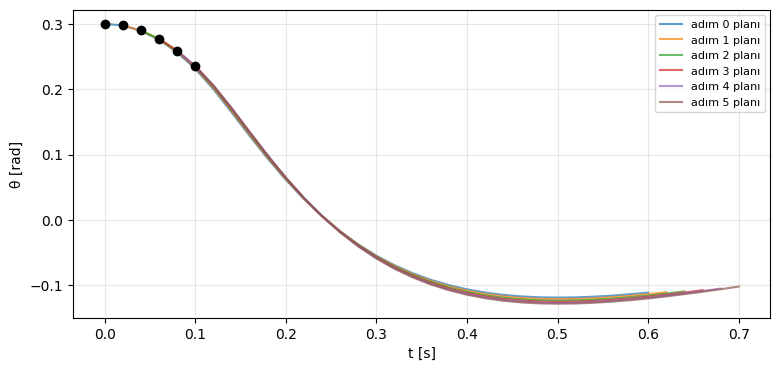

In [23]:
fn = cp.make_f(P)
s = s0.copy()
fig, ax = plt.subplots(figsize=(9, 4))
for k in range(6):                                              # 6 kontrol adımı
    F = mpc30.act(s)
    t_basla = k * dt
    ax.plot(t_basla + t_plan, mpc30.S.value[2], "-", alpha=0.7, label=f"adım {k} planı")
    ax.plot(t_basla, s[2], "ko")                                # gerçek θ (siyah nokta)
    _, S_adim, _ = cp.simulate(fn, s, lambda t, s_: F, dt, dt, substeps=20)   # GERÇEK (doğrusal olmayan) sistem 1 adım
    s = S_adim[-1]
ax.set_xlabel("t [s]"); ax.set_ylabel("θ [rad]"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

In [24]:
def oturma_suresi(t, x, tol=0.02):
    d = np.where(np.abs(x) > tol)[0]
    return t[d[-1]] if len(d) else 0.0

print(f"{'N':>3} | {'ufuk':>6} | {'ort.':>7} | {'%95':>7} | {'en kötü':>8} | {'ilk çağrı':>9} | {'oturma':>6}")
for N in (5, 10, 30, 60):
    m = MPCController(A_d, B_d, Q, R, P_d, N=N, dt=dt, F_max=10.0, x_max=2.4, K_yedek=K_d)
    t, S, U = run_closed_loop(m, [0.5, 0, 0.1, 0], T=5.0, F_max=10.0, substeps=5)
    ms = 1000 * np.array(m.cozum_sureleri)
    print(f"{N:3d} | {N*dt:5.2f}s | {ms[1:].mean():5.2f}ms | {np.percentile(ms[1:], 95):5.2f}ms | "
          f"{ms[1:].max():6.2f}ms | {ms[0]:7.1f}ms | {oturma_suresi(t, S[:, 0]):5.2f}s")

  N |   ufuk |    ort. |     %95 |  en kötü | ilk çağrı | oturma
  5 |  0.10s |  1.32ms |  1.69ms |   2.14ms |    17.6ms |  2.50s
 10 |  0.20s |  1.84ms |  2.36ms |   2.71ms |    27.7ms |  2.50s
 30 |  0.60s |  5.37ms |  7.87ms |   8.82ms |    72.5ms |  2.50s
 60 |  1.20s | 14.06ms | 19.73ms |  27.20ms |   147.2ms |  2.50s


LQR        : en büyük x = 91.42 m
MPC (N=30) : en büyük x = 2.29 m


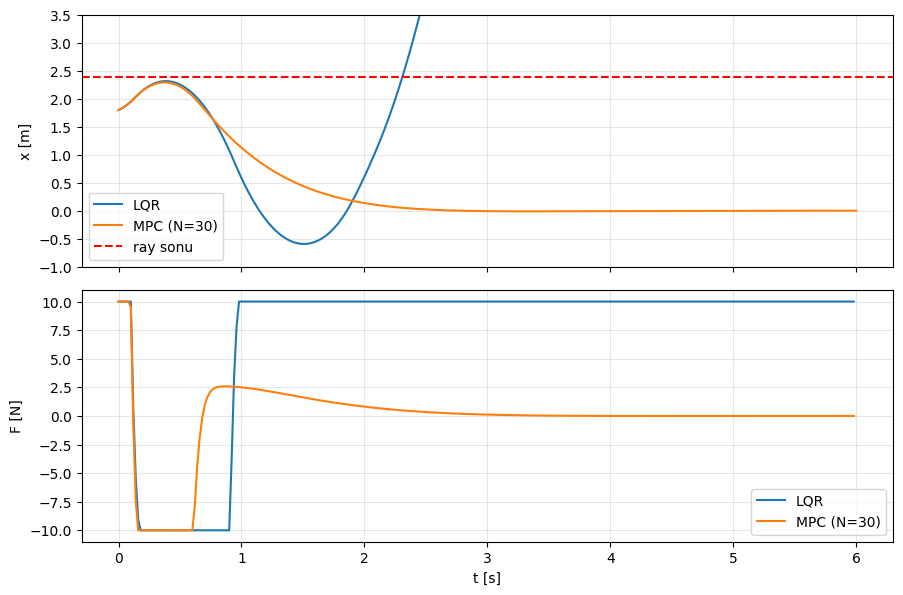

In [25]:
s_ray = [1.8, 1.0, 0.0, 0.0]
mpc_r = MPCController(A_d, B_d, Q, R, P_d, N=30, dt=dt, F_max=10.0, x_max=2.4, K_yedek=K_d)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ad, ctrl in {"LQR": LQRController(K_d), "MPC (N=30)": mpc_r}.items():
    with np.errstate(all="ignore"):
        t, S, U = run_closed_loop(ctrl, s_ray, T=6.0, F_max=10.0, substeps=5)
    ax[0].plot(t, S[:, 0], label=ad); ax[1].plot(t[:-1], U, label=ad)
    print(f"{ad:11s}: en büyük x = {np.nanmax(S[:, 0]):.2f} m")
ax[0].axhline(2.4, color="r", ls="--", label="ray sonu"); ax[0].set_ylim(-1, 3.5); ax[0].set_ylabel("x [m]")
ax[1].set_ylabel("F [N]"); ax[1].set_xlabel("t [s]")
for a in ax: a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

In [26]:
def ilk_basarisiz(yap, acilar=range(28, 46)):
    for d in acilar:
        with np.errstate(all="ignore"):
            _, S, _ = run_closed_loop(yap(), [0, 0, np.radians(d), 0], T=10.0, F_max=10.0, substeps=5)
        if not basarili(S):
            return d
    return None

print("LQR Bryson :", ilk_basarisiz(lambda: LQRController(K_d)), "°")
for N in (10, 30):
    print(f"MPC N={N:2d}  :", ilk_basarisiz(lambda: MPCController(A_d, B_d, Q, R, P_d, N=N, dt=dt, K_yedek=K_d)), "°")

LQR Bryson : 32 °


c:\Users\USER\miniconda3\envs\GNC_env\lib\site-packages\cvxpy\problems\problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


MPC N=10  : 33 °
MPC N=30  : 34 °
